<a href="https://colab.research.google.com/github/InfinitePraveen/Iris_flower_classification/blob/main/Iris_flower_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df = sns.load_dataset('iris')

In [ ]:
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [ ]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
df.isnull().sum()

,0
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


In [ ]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [ ]:
df['species'].value_counts()

,count
species,
setosa,50
versicolor,50
virginica,50


In [ ]:
df_encoded = pd.get_dummies(df, columns=['species'], prefix='species').astype("int")
display(df_encoded.head())

,sepal_length,sepal_width,petal_length,petal_width,species_0,species_1,species_2
0,5,3,1,0,1,0,0
1,4,3,1,0,1,0,0
2,4,3,1,0,1,0,0
3,4,3,1,0,1,0,0
4,5,3,1,0,1,0,0


<Axes: >

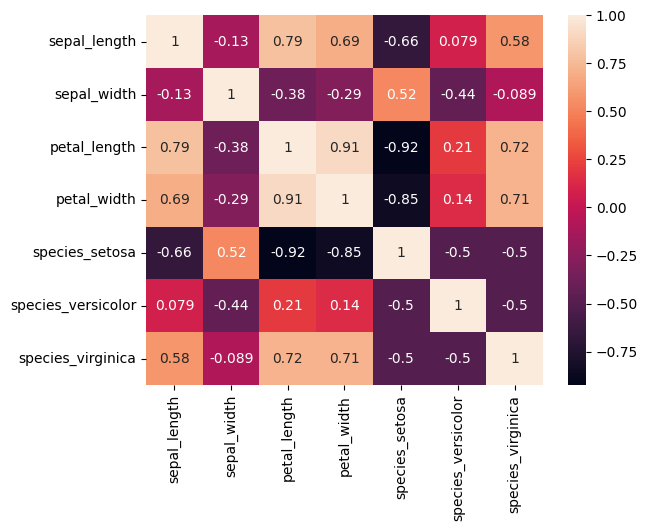

In [ ]:
sns.heatmap(df_encoded.corr(),annot=True)

In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['species'] = le.fit_transform(df['species'])

In [ ]:
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


<Axes: >

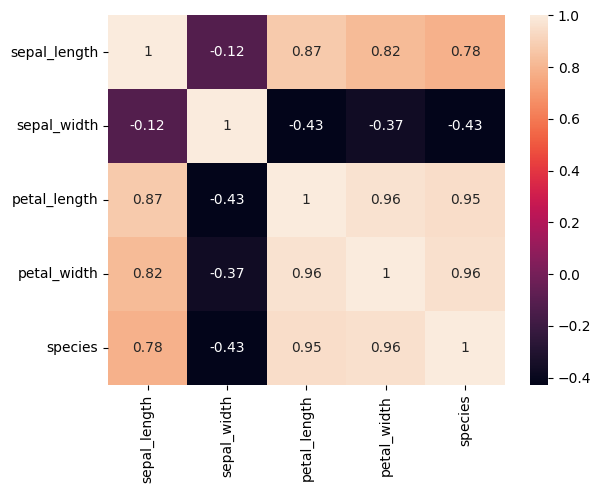

In [ ]:
sns.heatmap(df.corr(),annot=True)

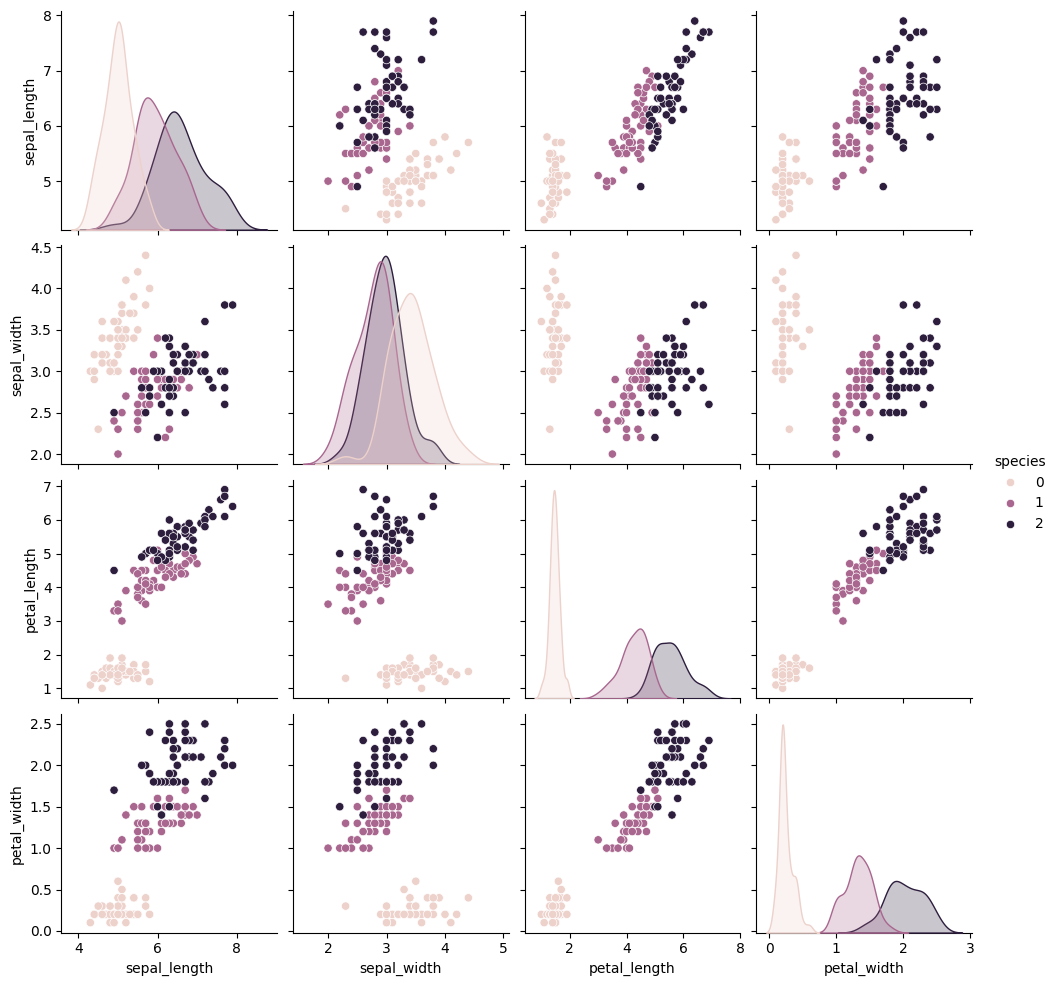

In [ ]:
sns.pairplot(df,hue='species')

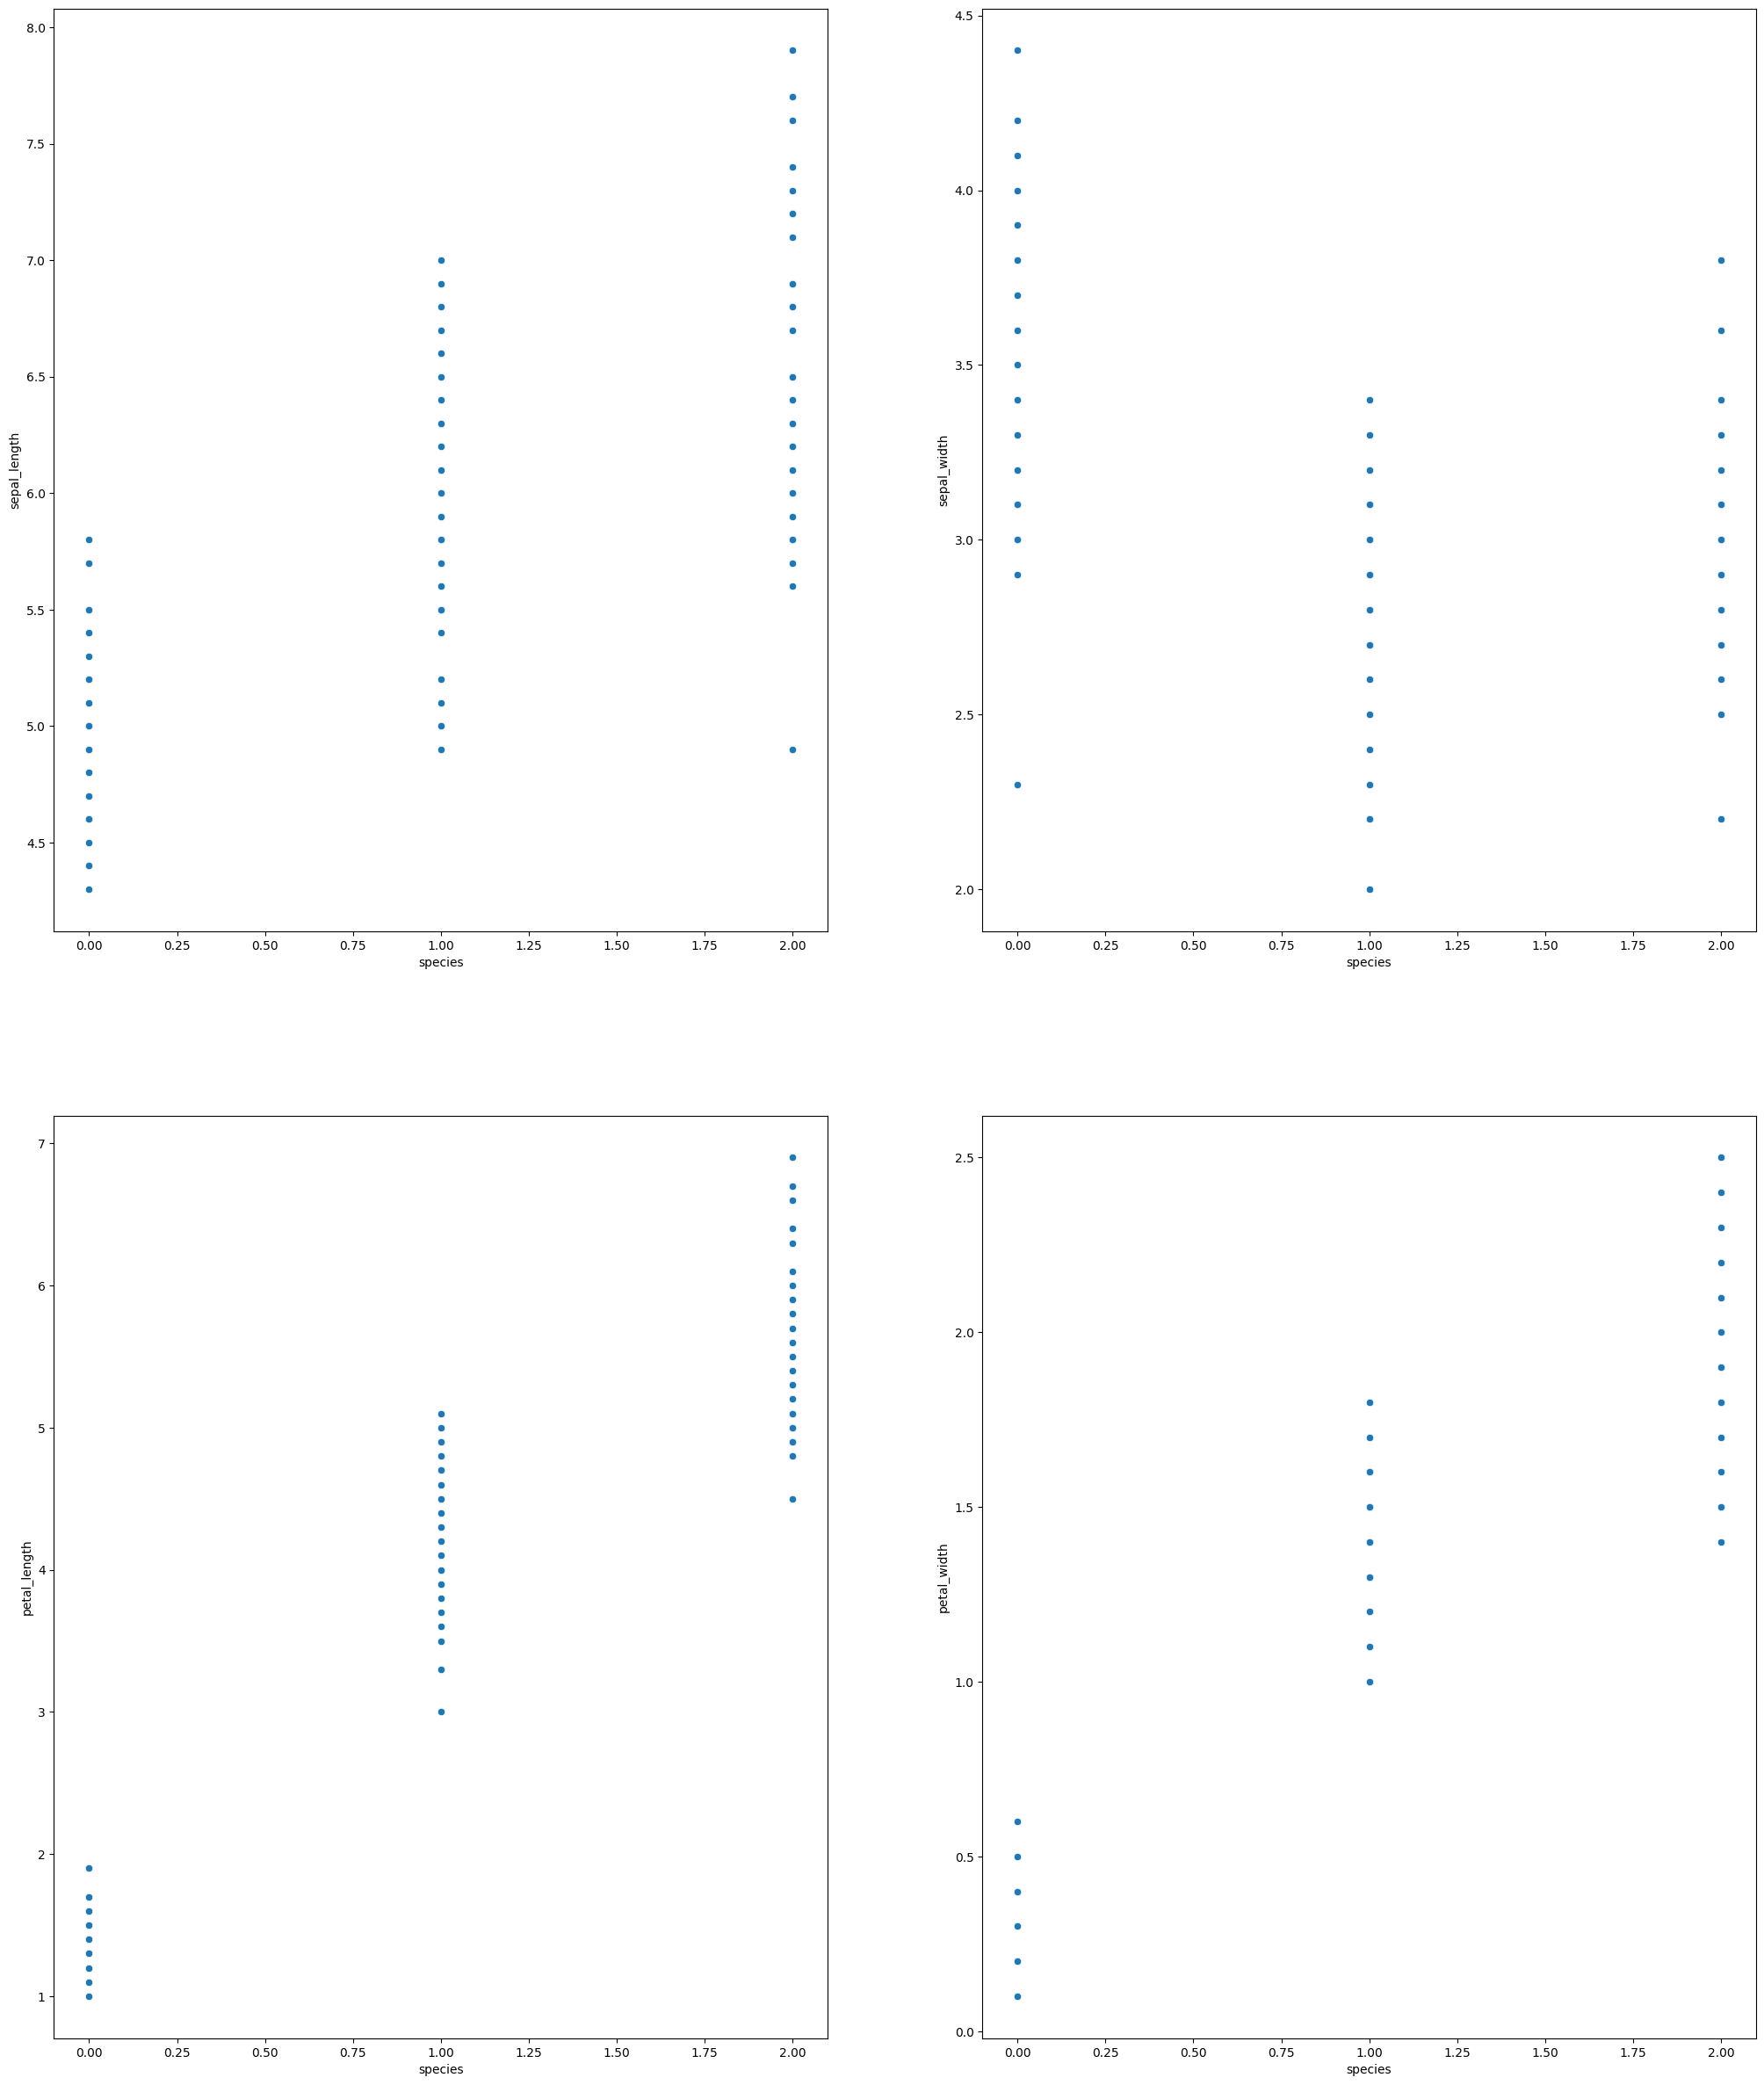

In [ ]:
columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
plt.figure(figsize=(25, 30))
for column in columns:
    plt.subplot(2, 2, columns.index(column) + 1)
    sns.scatterplot(x='species', y=column, data=df)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
X = df.drop('species', axis=1)
y = df['species']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Logistic Regression

In [ ]:
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train, y_train)
y_pred_log_reg = log_reg.predict(X_test)
accuracy_log_reg = accuracy_score(y_test, y_pred_log_reg)
print(f"Logistic Regression Accuracy: {accuracy_log_reg:.4f}")
print("Classification Report (Logistic Regression):")
print(classification_report(y_test, y_pred_log_reg))
print("Confusion Matrix (Logistic Regression):")
print(confusion_matrix(y_test, y_pred_log_reg))

Logistic Regression Accuracy: 1.0000
Classification Report (Logistic Regression):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Confusion Matrix (Logistic Regression):
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


### K-Nearest Neighbors (KNN)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
accuracy_knn = accuracy_score(y_test, y_pred_knn)
print(f"KNN Accuracy: {accuracy_knn:.4f}")
print("Classification Report (KNN):")
print(classification_report(y_test, y_pred_knn))
print("Confusion Matrix (KNN):")
print(confusion_matrix(y_test, y_pred_knn))

KNN Accuracy: 1.0000
Classification Report (KNN):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Confusion Matrix (KNN):
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


### Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dtree = DecisionTreeClassifier(random_state=42)
dtree.fit(X_train, y_train)
y_pred_dtree = dtree.predict(X_test)
accuracy_dtree = accuracy_score(y_test, y_pred_dtree)
print(f"Decision Tree Accuracy: {accuracy_dtree:.4f}")
print("Classification Report (Decision Tree):")
print(classification_report(y_test, y_pred_dtree))
print("Confusion Matrix (Decision Tree):")
print(confusion_matrix(y_test, y_pred_dtree))

Decision Tree Accuracy: 1.0000
Classification Report (Decision Tree):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Confusion Matrix (Decision Tree):
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


### Support Vector Machine (SVM)

In [ ]:
from sklearn.svm import SVC

svm = SVC(random_state=42)
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)
accuracy_svm = accuracy_score(y_test, y_pred_svm)
print(f"SVM Accuracy: {accuracy_svm:.4f}")
print("Classification Report (SVM):")
print(classification_report(y_test, y_pred_svm))
print("Confusion Matrix (SVM):")
print(confusion_matrix(y_test, y_pred_svm))

SVM Accuracy: 1.0000
Classification Report (SVM):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Confusion Matrix (SVM):
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


## Model Comparison

/tmp/ipykernel_9322/2384322627.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=models, y=scores, palette='viridis')


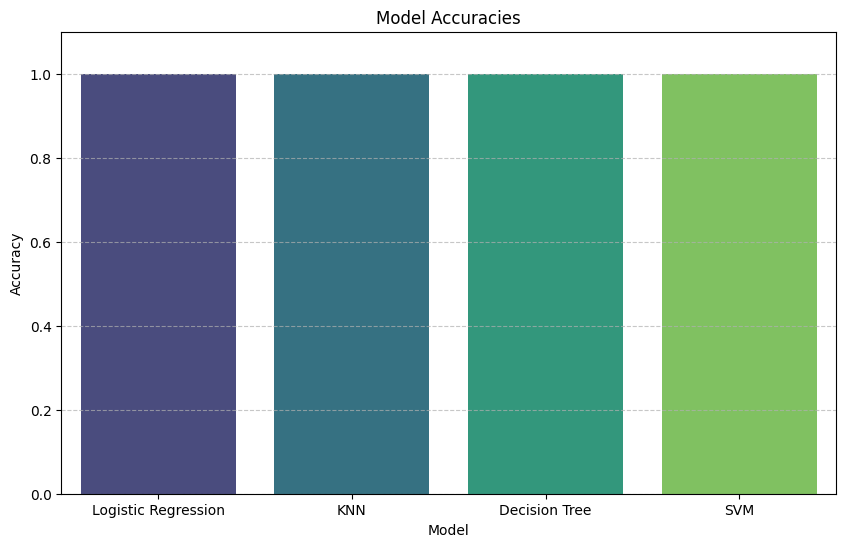


The best performing model is Logistic Regression with an accuracy of 1.0000.
All models achieved the same accuracy on this dataset.


In [ ]:
accuracies = {
    'Logistic Regression': accuracy_log_reg,
    'KNN': accuracy_knn,
    'Decision Tree': accuracy_dtree,
    'SVM': accuracy_svm
}

models = list(accuracies.keys())
scores = list(accuracies.values())

plt.figure(figsize=(10, 6))
sns.barplot(x=models, y=scores, palette='viridis')
plt.title('Model Accuracies')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.ylim(0, 1.1) # Set y-axis limit to 0-1 for accuracy scores
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

best_model = max(accuracies, key=accuracies.get)
best_accuracy = accuracies[best_model]

print(f"\nThe best performing model is {best_model} with an accuracy of {best_accuracy:.4f}.")

if all(s == scores[0] for s in scores): # Check if all scores are the same
    print("All models achieved the same accuracy on this dataset.")